In [ ]:
import torch
print(torch.__version__)

In [11]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

dyld[79542]: Library not loaded: /usr/lib/libhvf.dylib
  Referenced from: <15A54305-09C3-33F9-BB7F-5B42FD775C8E> /opt/homebrew/Cellar/freetype/2.15.0/lib/libfreetype.6.dylib
  Reason: tried: '/usr/lib/libhvf.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/usr/lib/libhvf.dylib' (no such file), '/usr/lib/libhvf.dylib' (no such file, not in dyld cache)
Matplotlib is building the font cache; this may take a moment.


In [6]:
def f(x):
    return 3*x**2 - 4*x + 5

In [7]:
f(3.0)

20.0

Scale values to feed in

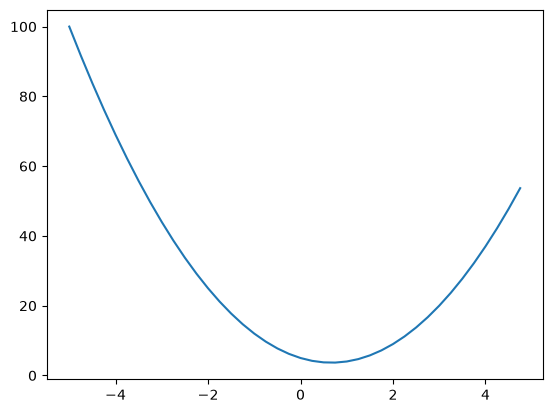

In [12]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

Derivative should be seen as a measurement of a slope - using basic words

In [13]:
h = 0.000001
x = 2/3
(f(x+h) - f(x))/h

-21.999997002808414

In [14]:
a = 2
b = -3
c = -10
d = a*b + c

print(d)

-16


Calculating derivative dx - more complicated example

Licząc pochodną cząstkową po a, c znika,  zostaje samo b stad wynik 'slope' = -3 = b

Działa to tak samo dla b - robiac pochodna cząstkową po b zostaje 1*a z analizy

In [18]:
h = 0.0001

a = 2
b = -3
c = 10

d1 = a*b + c
a += h
d2 = a*b + c

print('d1', d1)
print('d2', d2)

print('slope', (d2 - d1)/h)

d1 -16
d2 -16.000300000000003
slope -3.0000000000285354


In [ ]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0 # 0 is a basic value - means that this particular value has no affect on loss function L
        self._prev = set(_children)
        self._op = _op
        self.label = label

    # Provide nice looking expression - will be used in print() if no __str__ defined
    def __repr__(self) -> str:
        return f"Value(data={self.data})"

    def __add__(self, other) -> Value:
        return Value(self.data + other.data, (self, other), '+')

    def __mul__(self, other) -> Value:
        return Value(self.data * other.data, (self, other), '*')

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        return out

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')

e = a*b; e.label = 'e'
d = e+c; d.label = 'd'

f = Value(-2.0, label='f')
L = f*d; L.label='L'
L

Value(data=-8.0)

In [32]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [30]:
d._op

'+'

Crating graphic visualization using graphviz API

In [58]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes n edges in a graph using recursion
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root) # recursion start point
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={'rankdir': 'LR'}) # LR - left to right

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # for any value in the graph create rectangular ('record') node for it
        dot.node(name=uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if value is result of some operation create an op node for it
            dot.node(name = uid + n._op, label = n._op)

            #and connect thos node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


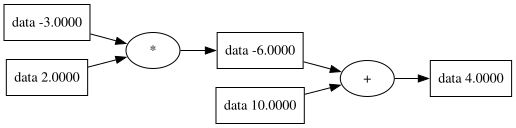

In [42]:
draw_dot(d)

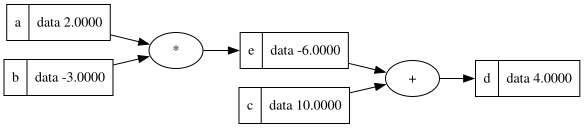

In [50]:
draw_dot(d)

L is a output(value) of the forward pass

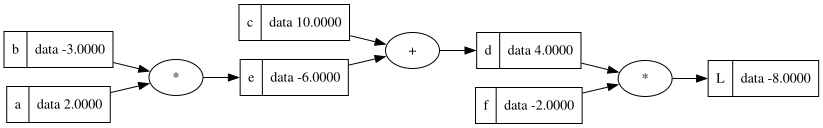

In [ ]:
draw_dot(L)

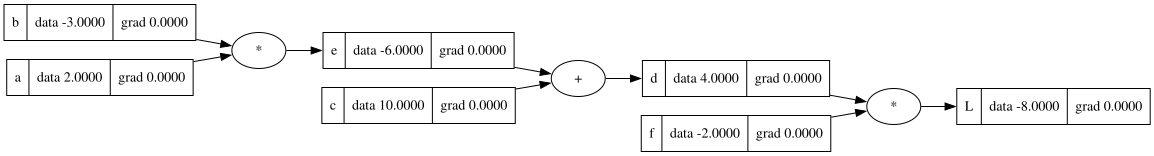

In [62]:
draw_dot(L)

In [79]:
L.grad = 1.0; d.grad = -2

## Backpropagation

In [ ]:
def lol():

    h = 0.00001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = f*d; L.label='L'
    L1 = L.data

    a = Value(2.0 + h, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = f*d; L.label='L'
    L2 = L.data

    print((L2 - L1)/h)
lol()

6.000000000128124


The most tricky part is deriving dL/dc (end of backpropagation) bcs we dont have c in L - we only know the c impact on d and d impact on L.

fist we do dd/dc where d = c + e
which comes to 1.0

Solution of this problem is chain rule



CHAIN RULE

dz/dx = dz/dy*dy/dx 

So its a product of change of theese two.

Knowing that we calculate gradient of c and e manually for now


dd/dc = 1.0
dd/de = 1.0 

d = c + e

dL/dc = (dL/dd) * (dd/dc) = -2 * 1 = -2

In [74]:
c.grad = -2.0; e.grad = -2.0

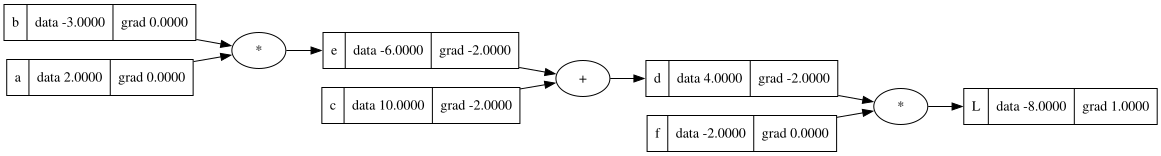

In [80]:
draw_dot(L)

Summary: Backpropagation is a recursive appliaction of chain rule - backwards through the computation graph

# Neurons

Neurons contain summary of products of weight and x, plus bias - evaluated by ReLU or tanh function

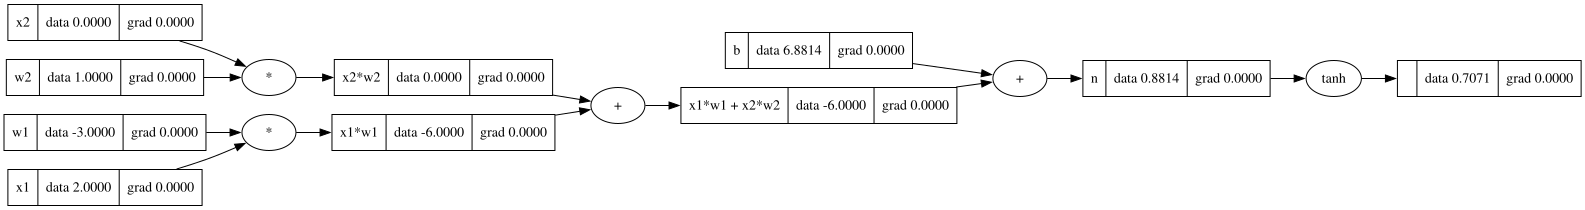

In [89]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh()
draw_dot(o)

In [ ]:
x1w1.grad = 0.5
x2w2.grad = 0.5

x1w1x2w2.grad = 0.5
b.grad = 0.5

n.grad = 0.5

o.grad = 0.5